In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

In [2]:
from google.colab import files
uploaded = files.upload()

Saving Sample - Superstore.csv to Sample - Superstore.csv


In [3]:
df = pd.read_csv('Sample - Superstore.csv', encoding='latin1')

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [4]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 9994
Number of columns: 21


## 2. Data Cleaning and Preparation

This section evaluates data quality by identifying
missing values, duplicate records, incorrect data
types, and potential inconsistencies to ensure
accurate and reliable business analysis.

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [6]:
print("Missing values by column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values by column:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

Total missing values: 0


In [7]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


In [8]:
df[['Sales', 'Quantity', 'Discount', 'Profit']].describe()

,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000
mean,229.858001,3.789574,0.156203,28.656896
std,623.245101,2.225110,0.206452,234.260108
min,0.444000,1.000000,0.000000,-6599.978000
25%,17.280000,2.000000,0.000000,1.728750
50%,54.490000,3.000000,0.200000,8.666500
75%,209.940000,5.000000,0.200000,29.364000
max,22638.480000,14.000000,0.800000,8399.976000


### Initial Data Quality Findings

The dataset contains 9,994 records and 21 variables, with no missing values or exact duplicate records. Preliminary descriptive statistics indicate average sales of USD 229.86 and average profit of USD 28.66 per record. The average discount is 15.62%, with a maximum discount of 80%.

The presence of negative profit values highlights the importance of investigating loss-making transactions. Additionally, the difference between mean and median sales suggests a right-skewed distribution.

The dataset is suitable for further analysis following data type conversion and additional validation.

In [9]:
df['Order Date'] = pd.to_datetime(
    df['Order Date'], format='%m/%d/%Y'
)

df['Ship Date'] = pd.to_datetime(
    df['Ship Date'], format='%m/%d/%Y'
)

print(df[['Order Date', 'Ship Date']].dtypes)

Order Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object


In [10]:
print("Duplicate Row IDs:",
      df['Row ID'].duplicated().sum())

print("Invalid sales:",
      (df['Sales'] <= 0).sum())

print("Invalid quantities:",
      (df['Quantity'] <= 0).sum())

print("Invalid discounts:",
      ((df['Discount'] < 0) |
       (df['Discount'] > 1)).sum())

print("Invalid shipping dates:",
      (df['Ship Date'] < df['Order Date']).sum())

Duplicate Row IDs: 0
Invalid sales: 0
Invalid quantities: 0
Invalid discounts: 0
Invalid shipping dates: 0


In [11]:
df['Year'] = df['Order Date'].dt.year

df['Month'] = df['Order Date'].dt.month

df['Month Name'] = df['Order Date'].dt.month_name()

df['Quarter'] = df['Order Date'].dt.quarter

df['Profit Margin'] = (df['Profit'] / df['Sales']) * 100

df['Shipping Days'] = (
    df['Ship Date'] - df['Order Date']
).dt.days

In [12]:
df[['Order Date', 'Year', 'Month Name',
    'Quarter', 'Profit Margin',
    'Shipping Days']].head()

,Order Date,Year,Month Name,Quarter,Profit Margin,Shipping Days
0,2016-11-08,2016,November,4,16.00,3
1,2016-11-08,2016,November,4,30.00,3
2,2016-06-12,2016,June,2,47.00,4
3,2015-10-11,2015,October,4,-40.00,7
4,2015-10-11,2015,October,4,11.25,7


In [13]:
print("Updated dataset dimensions:", df.shape)

Updated dataset dimensions: (9994, 27)


The dataset contains 9,994 records and 21 variables,
with no missing values or exact duplicate records.
Preliminary descriptive statistics indicate average
sales of USD 229.86 and average profit of USD 28.66
per record. The average discount is 15.62%, with a
maximum discount of 80%.

## 3. Business Performance and KPI Analysis

This section evaluates overall business performance
using key performance indicators, including total
revenue, total profit, profit margin, total orders,
customer count, and average order value.

In [14]:
total_revenue = df['Sales'].sum()

total_profit = df['Profit'].sum()

total_orders = df['Order ID'].nunique()

total_customers = df['Customer ID'].nunique()

total_units = df['Quantity'].sum()

profit_margin = (total_profit / total_revenue) * 100

average_order_value = total_revenue / total_orders

revenue_per_customer = total_revenue / total_customers

In [15]:
print("BUSINESS PERFORMANCE SUMMARY")
print("-" * 40)

print(f"Total Revenue: ${total_revenue:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Profit Margin: {profit_margin:.2f}%")
print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Total Units Sold: {total_units:,}")
print(f"Average Order Value: ${average_order_value:,.2f}")
print(f"Revenue per Customer: ${revenue_per_customer:,.2f}")

BUSINESS PERFORMANCE SUMMARY
----------------------------------------
Total Revenue: $2,297,200.86
Total Profit: $286,397.02
Profit Margin: 12.47%
Total Orders: 5,009
Total Customers: 793
Total Units Sold: 37,873
Average Order Value: $458.61
Revenue per Customer: $2,896.85


## 4. Exploratory Data Analysis

This section examines sales trends, profitability,
product performance, regional differences, and
customer behavior to identify opportunities for
business improvement.

### 4.1 Annual Sales and Profit Analysis

In [16]:
sns.set_theme(style='whitegrid')

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 11

primary_color = '#17365D'
secondary_color = '#5B9BD5'

In [17]:
annual_performance = df.groupby('Year').agg(
    Revenue=('Sales', 'sum'),
    Profit=('Profit', 'sum'),
    Orders=('Order ID', 'nunique')
).reset_index()

annual_performance['Profit Margin (%)'] = (
    annual_performance['Profit'] /
    annual_performance['Revenue']
) * 100

annual_performance['Revenue Growth (%)'] = (
    annual_performance['Revenue'].pct_change() * 100
)

annual_performance.round(2)

,Year,Revenue,Profit,Orders,Profit Margin (%),Revenue Growth (%)
0,2014,484247.50,49543.97,969,10.23,NaN
1,2015,470532.51,61618.60,1038,13.10,-2.83
2,2016,609205.60,81795.17,1315,13.43,29.47
3,2017,733215.26,93439.27,1687,12.74,20.36


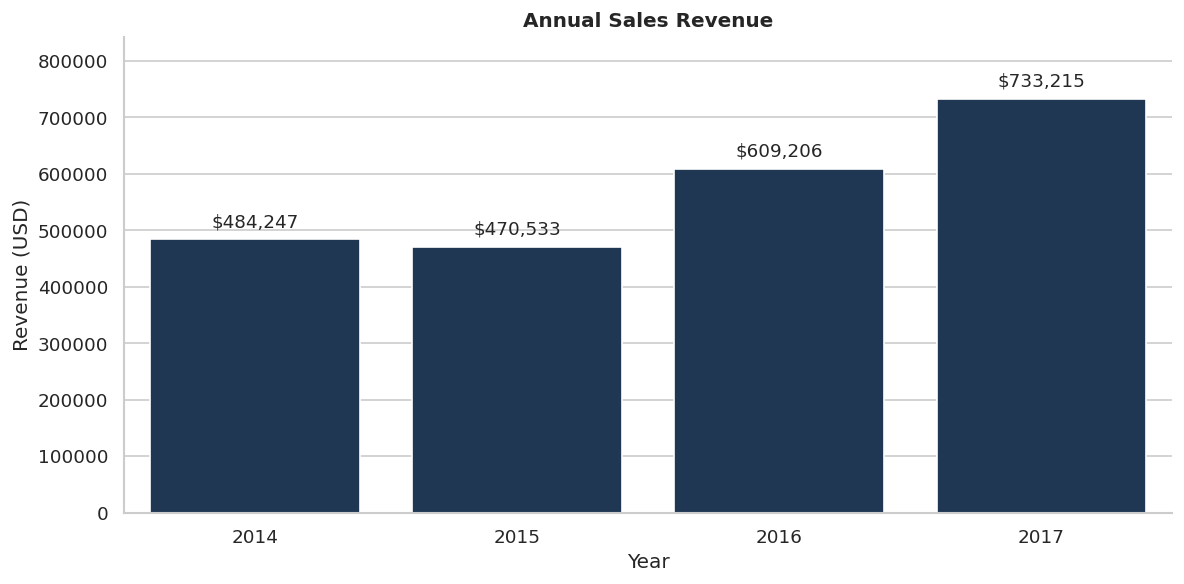

In [18]:
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=annual_performance,
    x='Year',
    y='Revenue',
    color=primary_color
)

for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f'${v:,.0f}' for v in container.datavalues],
        padding=5
    )

plt.title('Annual Sales Revenue', fontweight='bold')
plt.xlabel('Year')
plt.ylabel('Revenue (USD)')
plt.ylim(0, annual_performance['Revenue'].max() * 1.15)

sns.despine()
plt.tight_layout()
plt.show()

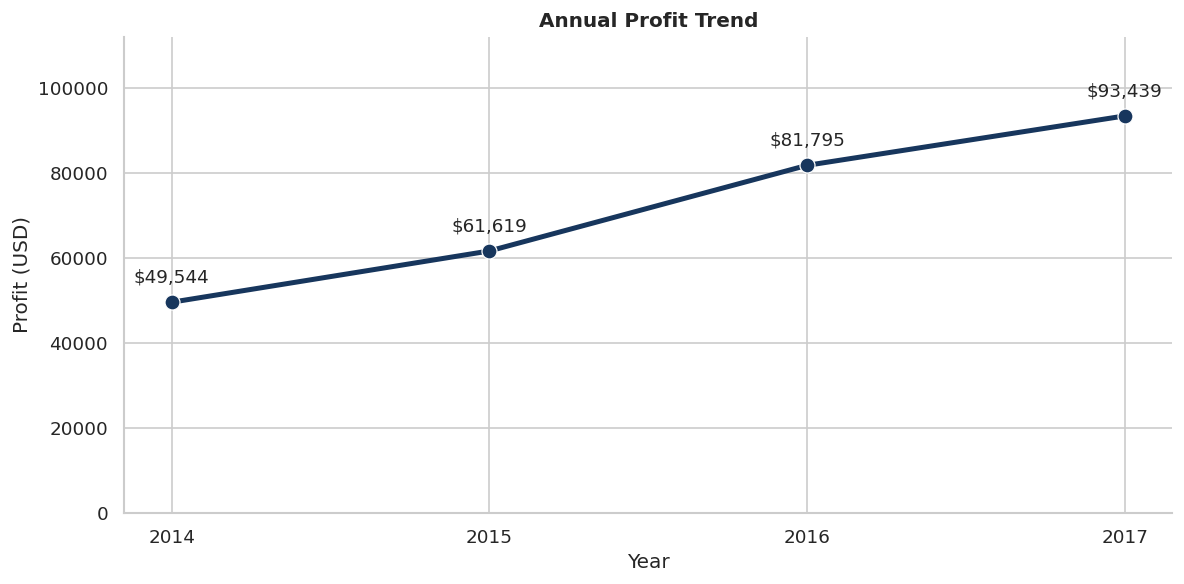

In [19]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=annual_performance,
    x='Year',
    y='Profit',
    marker='o',
    linewidth=3,
    markersize=9,
    color=primary_color
)

for x, y in zip(
    annual_performance['Year'],
    annual_performance['Profit']
):
    plt.annotate(
        f'${y:,.0f}',
        (x, y),
        xytext=(0, 12),
        textcoords='offset points',
        ha='center'
    )

plt.title('Annual Profit Trend', fontweight='bold')
plt.xlabel('Year')
plt.ylabel('Profit (USD)')
plt.xticks(annual_performance['Year'])
plt.ylim(0, annual_performance['Profit'].max() * 1.2)

sns.despine()
plt.tight_layout()
plt.show()

### Annual Performance Findings

The company demonstrated substantial growth between 2014 and 2017, with total annual revenue increasing by approximately 51.41% and annual profit increasing by 88.60%.

Although revenue declined by 2.83% in 2015, the profit margin improved from 10.23% to 13.10%. The strongest annual revenue growth occurred in 2016, reaching 29.47%.

In 2017, the company achieved its highest annual revenue and profit. However, the profit margin declined from 13.43% to 12.74%, suggesting the need to investigate potential factors affecting profitability, including discounts and product mix.

### 4.2 Monthly Sales Trend Analysis

This analysis examines monthly revenue fluctuations
to identify seasonal patterns and periods of high
and low business activity.

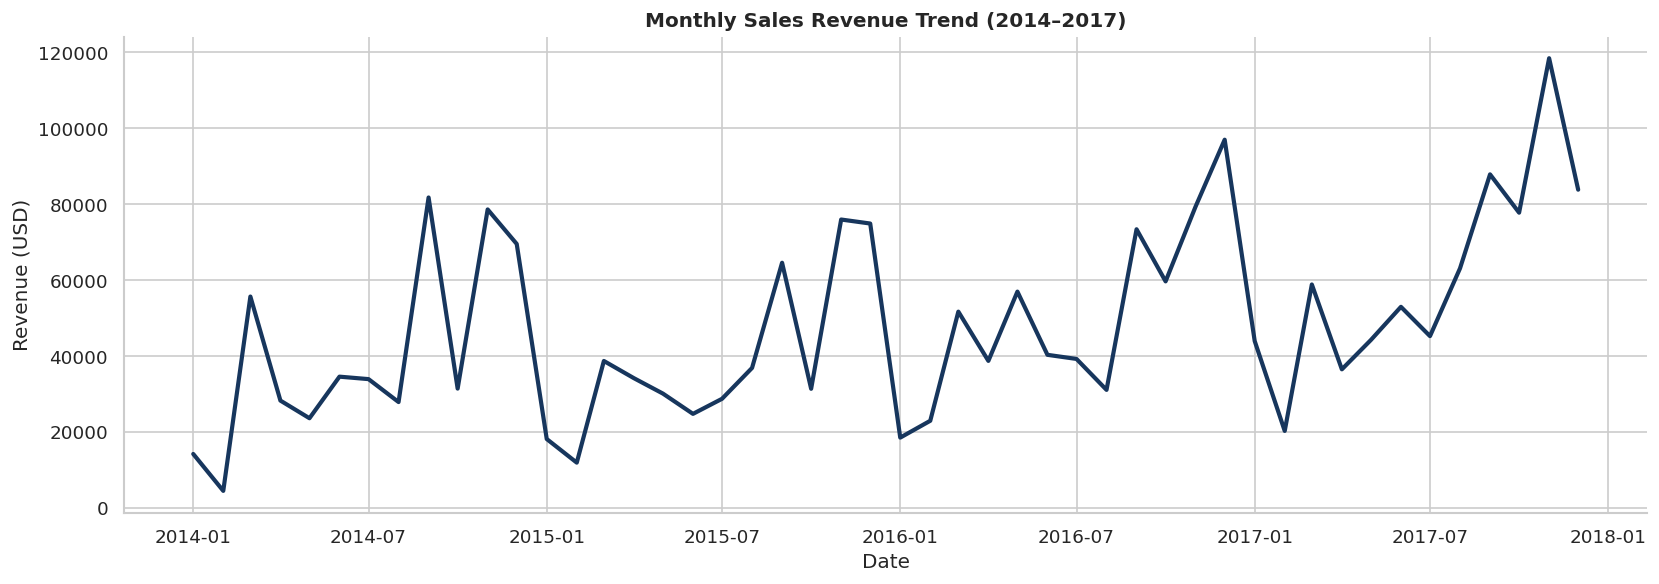

In [20]:
monthly_sales = (
    df.set_index('Order Date')['Sales']
    .resample('MS')
    .sum()
    .reset_index()
)

plt.figure(figsize=(14, 5))

sns.lineplot(
    data=monthly_sales,
    x='Order Date',
    y='Sales',
    color=primary_color,
    linewidth=2.5
)

plt.title(
    'Monthly Sales Revenue Trend (2014–2017)',
    fontweight='bold'
)

plt.xlabel('Date')
plt.ylabel('Revenue (USD)')

sns.despine()
plt.tight_layout()
plt.show()

In [21]:
top_months = monthly_sales.nlargest(5, 'Sales').copy()

top_months['Order Date'] = (
    top_months['Order Date'].dt.strftime('%B %Y')
)

top_months.round(2)

,Order Date,Sales
46,November 2017,118447.82
35,December 2016,96999.04
44,September 2017,87866.65
47,December 2017,83829.32
8,September 2014,81777.35


### Monthly Sales Findings

Monthly revenue analysis reveals fluctuations in sales performance and potential seasonal patterns. November 2017 recorded the highest monthly revenue of USD 118,447.82, followed by December 2016 with USD 96,999.04.

Three of the five highest-revenue months occurred in 2017, reflecting the company's overall revenue growth. Sales generally appear stronger during the latter part of the year, while the beginning of the year experiences relatively lower demand.

These findings suggest that management could benefit from adjusting inventory levels, marketing campaigns, and staffing strategies in anticipation of peak sales periods.

### 4.3 Product Category Performance Analysis

This section evaluates revenue, profit, sales volume,
and profit margins across product categories to
identify high-performing and underperforming
business segments.

In [22]:
category_performance = df.groupby('Category').agg(
    Revenue=('Sales', 'sum'),
    Profit=('Profit', 'sum'),
    Units_Sold=('Quantity', 'sum'),
    Average_Discount=('Discount', 'mean')
).reset_index()

category_performance['Profit Margin (%)'] = (
    category_performance['Profit'] /
    category_performance['Revenue']
) * 100

category_performance['Revenue Share (%)'] = (
    category_performance['Revenue'] /
    total_revenue
) * 100

category_performance['Average_Discount'] *= 100

category_performance.sort_values(
    'Revenue', ascending=False
).round(2)

,Category,Revenue,Profit,Units_Sold,Average_Discount,Profit Margin (%),Revenue Share (%)
2,Technology,836154.03,145454.95,6939,13.23,17.40,36.4
0,Furniture,741999.80,18451.27,8028,17.39,2.49,32.3
1,Office Supplies,719047.03,122490.80,22906,15.73,17.04,31.3


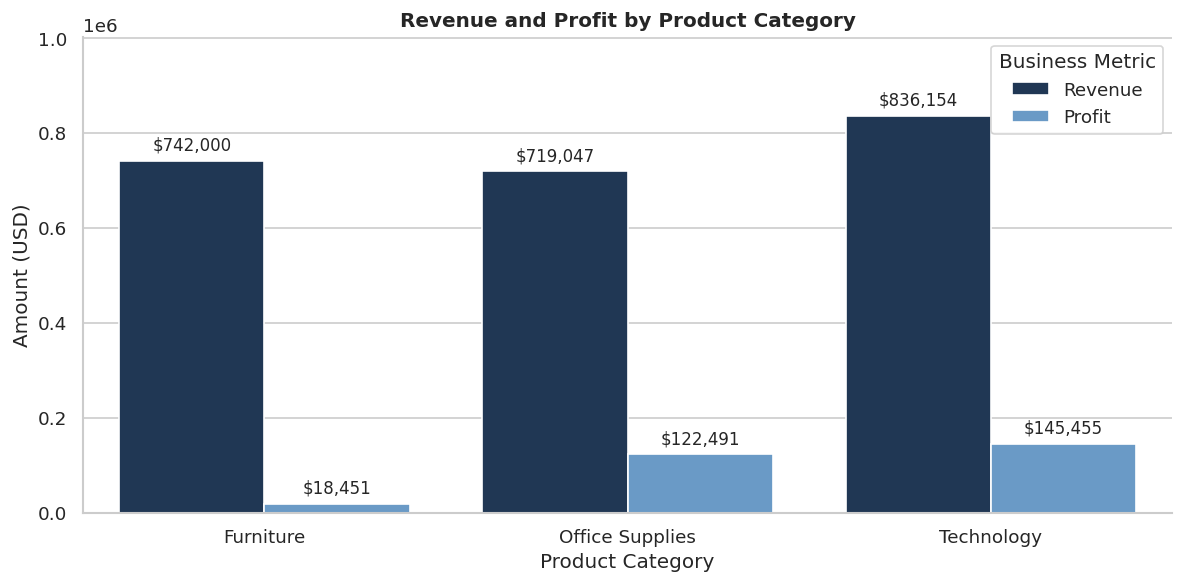

In [23]:
plt.figure(figsize=(10, 5))

category_plot = category_performance.melt(
    id_vars='Category',
    value_vars=['Revenue', 'Profit'],
    var_name='Metric',
    value_name='Amount'
)

ax = sns.barplot(
    data=category_plot,
    x='Category',
    y='Amount',
    hue='Metric',
    palette=[primary_color, secondary_color]
)

for container in ax.containers:
    ax.bar_label(
        container,
        labels=[
            f'${v:,.0f}'
            for v in container.datavalues
        ],
        padding=4,
        fontsize=10
    )

plt.title(
    'Revenue and Profit by Product Category',
    fontweight='bold'
)

plt.xlabel('Product Category')
plt.ylabel('Amount (USD)')
plt.ylim(0, category_performance['Revenue'].max() * 1.2)
plt.legend(title='Business Metric')

sns.despine()
plt.tight_layout()
plt.show()

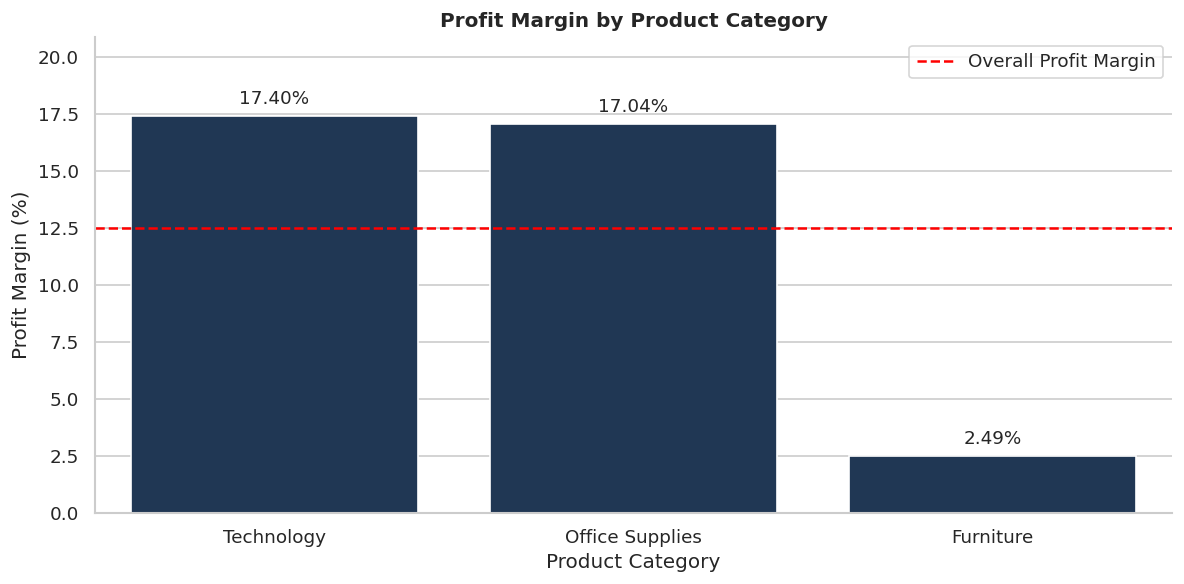

In [24]:
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=category_performance.sort_values(
        'Profit Margin (%)', ascending=False
    ),
    x='Category',
    y='Profit Margin (%)',
    color=primary_color
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.2f%%',
        padding=5
    )

plt.axhline(
    y=profit_margin,
    color='red',
    linestyle='--',
    label='Overall Profit Margin'
)

plt.title(
    'Profit Margin by Product Category',
    fontweight='bold'
)

plt.xlabel('Product Category')
plt.ylabel('Profit Margin (%)')
plt.ylim(0, category_performance['Profit Margin (%)'].max() * 1.2)
plt.legend()

sns.despine()
plt.tight_layout()
plt.show()

### 4.4 Product Sub-Category Profitability Analysis

In [25]:
subcategory_performance = df.groupby('Sub-Category').agg(
    Revenue=('Sales', 'sum'),
    Profit=('Profit', 'sum'),
    Units_Sold=('Quantity', 'sum')
).reset_index()

subcategory_performance['Profit Margin (%)'] = (
    subcategory_performance['Profit'] /
    subcategory_performance['Revenue']
) * 100

subcategory_performance = (
    subcategory_performance.sort_values(
        'Profit', ascending=False
    )
)

subcategory_performance.round(2)

,Sub-Category,Revenue,Profit,Units_Sold,Profit Margin (%)
6,Copiers,149528.03,55617.82,234,37.20
13,Phones,330007.05,44515.73,3289,13.49
0,Accessories,167380.32,41936.64,2976,25.05
12,Paper,78479.21,34053.57,5178,43.39
3,Binders,203412.73,30221.76,5974,14.86
5,Chairs,328449.10,26590.17,2356,8.10
14,Storage,223843.61,21278.83,3158,9.51
1,Appliances,107532.16,18138.01,1729,16.87
9,Furnishings,91705.16,13059.14,3563,14.24
7,Envelopes,16476.40,6964.18,906,42.27


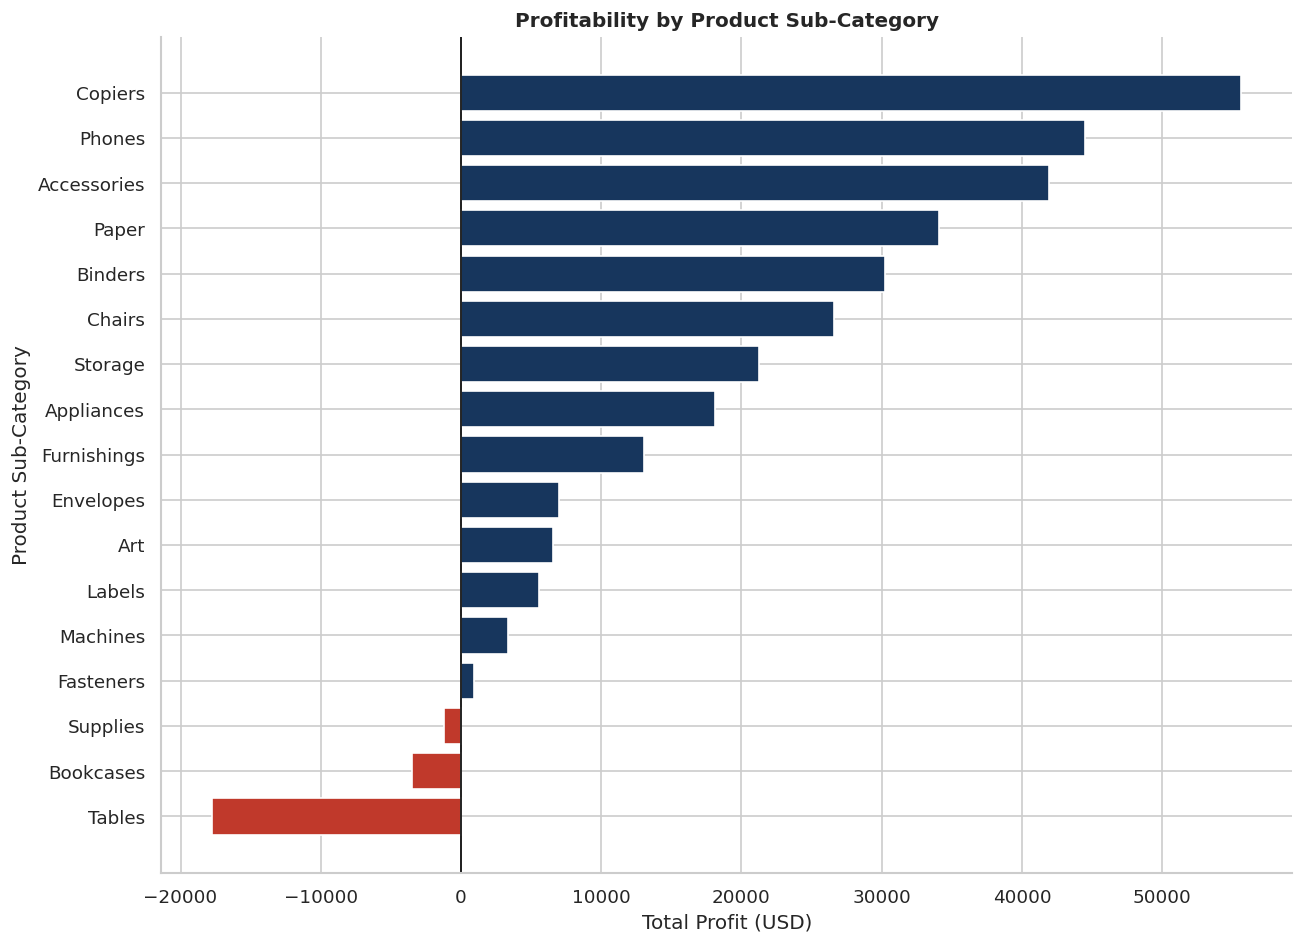

In [26]:
plt.figure(figsize=(11, 8))

colors = [
    '#17365D' if profit >= 0 else '#C0392B'
    for profit in subcategory_performance['Profit']
]

plt.barh(
    subcategory_performance['Sub-Category'],
    subcategory_performance['Profit'],
    color=colors
)

plt.axvline(0, color='black', linewidth=1)
plt.gca().invert_yaxis()

plt.title(
    'Profitability by Product Sub-Category',
    fontweight='bold'
)

plt.xlabel('Total Profit (USD)')
plt.ylabel('Product Sub-Category')

sns.despine()
plt.tight_layout()
plt.show()

### Product Category Findings

Technology emerged as the strongest product category, generating USD 836,154 in revenue and USD 145,455 in profit, with a profit margin of 17.40%.

Office Supplies also demonstrated strong profitability, achieving a profit margin of 17.04% and the highest sales volume among all categories.

However, Furniture generated approximately 32.30% of total revenue while contributing only 6.44% of total profit. Its profit margin of 2.49% was significantly below the overall company margin of 12.47%.

Furniture also recorded the highest average discount, suggesting that its pricing and discount strategies warrant further investigation.

In [27]:
loss_making_products = subcategory_performance[
    subcategory_performance['Profit'] < 0
].sort_values('Profit')

loss_making_products.round(2)

,Sub-Category,Revenue,Profit,Units_Sold,Profit Margin (%)
16,Tables,206965.53,-17725.48,1241,-8.56
4,Bookcases,114880.00,-3472.56,868,-3.02
15,Supplies,46673.54,-1189.10,647,-2.55


In [28]:
total_product_losses = loss_making_products['Profit'].sum()

print(f"Combined Losses: ${abs(total_product_losses):,.2f}")

Combined Losses: $22,387.14


### Product Sub-Category Findings

The sub-category analysis identified Copiers, Phones, and Accessories as the three largest contributors to total profit.

However, Tables, Bookcases, and Supplies recorded negative overall profitability, generating combined net losses of approximately USD 22,387.14.

Tables represented the largest source of losses, accounting for approximately 79.18% of the combined net losses across these three sub-categories.

Management should prioritize reviewing pricing strategies, discount policies, and product costs associated with these underperforming sub-categories.

### 4.5 Regional Performance Analysis

This section evaluates geographical differences
in revenue, profitability, customer demand,
and discount strategies to identify regional
business opportunities.

In [29]:
regional_performance = df.groupby('Region').agg(
    Revenue=('Sales', 'sum'),
    Profit=('Profit', 'sum'),
    Orders=('Order ID', 'nunique'),
    Customers=('Customer ID', 'nunique'),
    Average_Discount=('Discount', 'mean')
).reset_index()

regional_performance['Profit Margin (%)'] = (
    regional_performance['Profit'] /
    regional_performance['Revenue']
) * 100

regional_performance['Average_Discount'] *= 100

regional_performance.sort_values(
    'Revenue', ascending=False
).round(2)

,Region,Revenue,Profit,Orders,Customers,Average_Discount,Profit Margin (%)
3,West,725457.82,108418.45,1611,686,10.93,14.94
1,East,678781.24,91522.78,1401,674,14.54,13.48
0,Central,501239.89,39706.36,1175,629,24.04,7.92
2,South,391721.90,46749.43,822,512,14.73,11.93


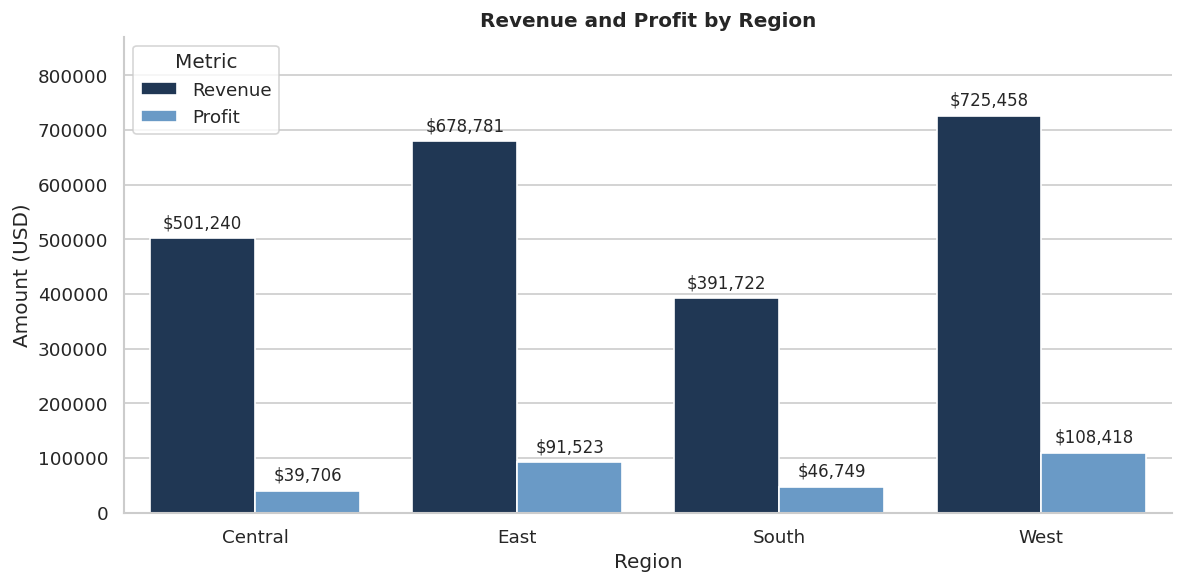

In [30]:
regional_plot = regional_performance.melt(
    id_vars='Region',
    value_vars=['Revenue', 'Profit'],
    var_name='Metric',
    value_name='Amount'
)

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=regional_plot,
    x='Region',
    y='Amount',
    hue='Metric',
    palette=[primary_color, secondary_color]
)

for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f'${v:,.0f}' for v in container.datavalues],
        padding=4,
        fontsize=10
    )

plt.title('Revenue and Profit by Region',
          fontweight='bold')

plt.xlabel('Region')
plt.ylabel('Amount (USD)')
plt.ylim(0, regional_performance['Revenue'].max() * 1.2)

sns.despine()
plt.tight_layout()
plt.show()

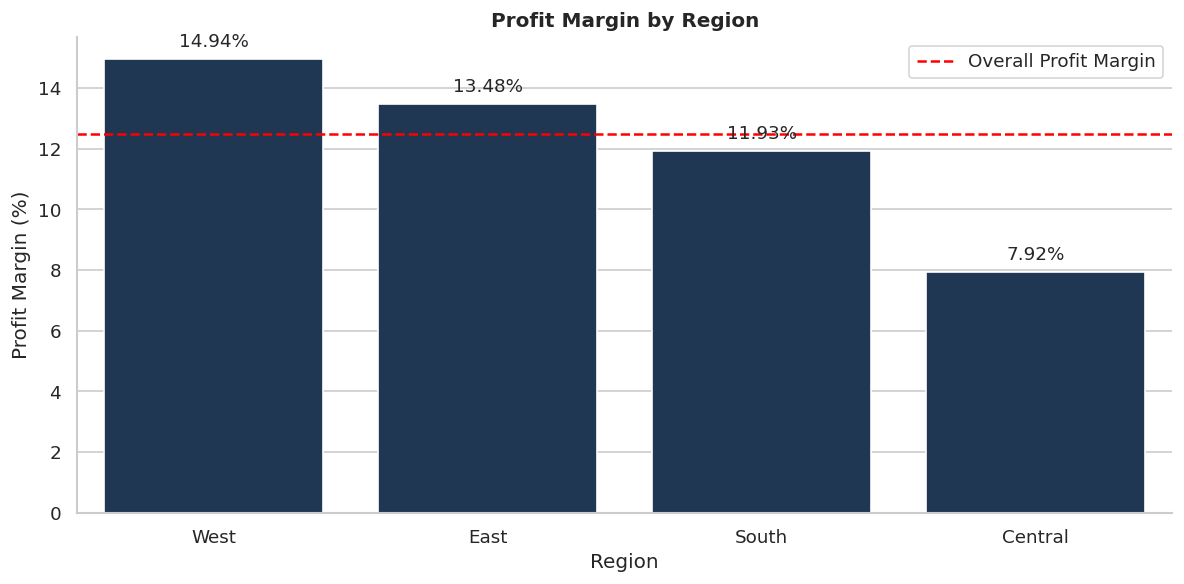

In [31]:
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=regional_performance.sort_values(
        'Profit Margin (%)', ascending=False
    ),
    x='Region',
    y='Profit Margin (%)',
    color=primary_color
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=5)

plt.axhline(
    profit_margin,
    color='red',
    linestyle='--',
    label='Overall Profit Margin'
)

plt.title('Profit Margin by Region', fontweight='bold')
plt.xlabel('Region')
plt.ylabel('Profit Margin (%)')
plt.legend()

sns.despine()
plt.tight_layout()
plt.show()

### Regional Performance Findings

The West region demonstrated the strongest overall business performance, generating approximately USD 725,458 in revenue and USD 108,418 in profit, with a profit margin of 14.94%.

The Central region recorded the lowest profit margin of 7.92%, despite generating more revenue than the South region. It also offered the highest average discount of 24.04%.

In contrast, the West region maintained the lowest average discount of 10.93% while achieving the highest profitability.

These findings suggest a potential association between discount strategies and regional profitability. Further statistical analysis is necessary to evaluate this relationship.

### 4.6 Customer Segment Analysis

This section evaluates customer segments based on
revenue, profitability, purchasing behavior, and
average order value to identify valuable customer
groups and business growth opportunities.

In [32]:
segment_performance = df.groupby('Segment').agg(
    Revenue=('Sales', 'sum'),
    Profit=('Profit', 'sum'),
    Orders=('Order ID', 'nunique'),
    Customers=('Customer ID', 'nunique'),
    Units_Sold=('Quantity', 'sum')
).reset_index()

segment_performance['Profit Margin (%)'] = (
    segment_performance['Profit'] /
    segment_performance['Revenue']
) * 100

segment_performance['Average Order Value'] = (
    segment_performance['Revenue'] /
    segment_performance['Orders']
)

segment_performance['Revenue per Customer'] = (
    segment_performance['Revenue'] /
    segment_performance['Customers']
)

segment_performance.sort_values(
    'Revenue', ascending=False
).round(2)

,Segment,Revenue,Profit,Orders,Customers,Units_Sold,Profit Margin (%),Average Order Value,Revenue per Customer
0,Consumer,1161401.34,134119.21,2586,409,19521,11.55,449.11,2839.61
1,Corporate,706146.37,91979.13,1514,236,11608,13.03,466.41,2992.15
2,Home Office,429653.15,60298.68,909,148,6744,14.03,472.67,2903.06


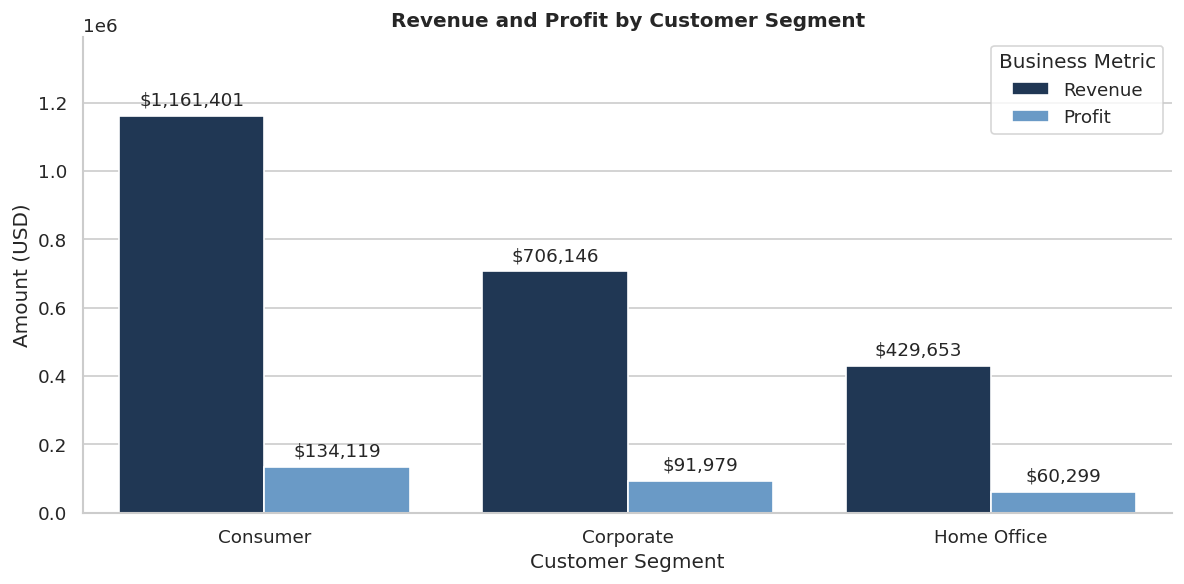

In [33]:
segment_plot = segment_performance.melt(
    id_vars='Segment',
    value_vars=['Revenue', 'Profit'],
    var_name='Metric',
    value_name='Amount'
)

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=segment_plot,
    x='Segment',
    y='Amount',
    hue='Metric',
    palette=[primary_color, secondary_color]
)

for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f'${v:,.0f}' for v in container.datavalues],
        padding=4
    )

plt.title(
    'Revenue and Profit by Customer Segment',
    fontweight='bold'
)

plt.xlabel('Customer Segment')
plt.ylabel('Amount (USD)')
plt.ylim(0, segment_performance['Revenue'].max() * 1.2)
plt.legend(title='Business Metric')

sns.despine()
plt.tight_layout()
plt.show()

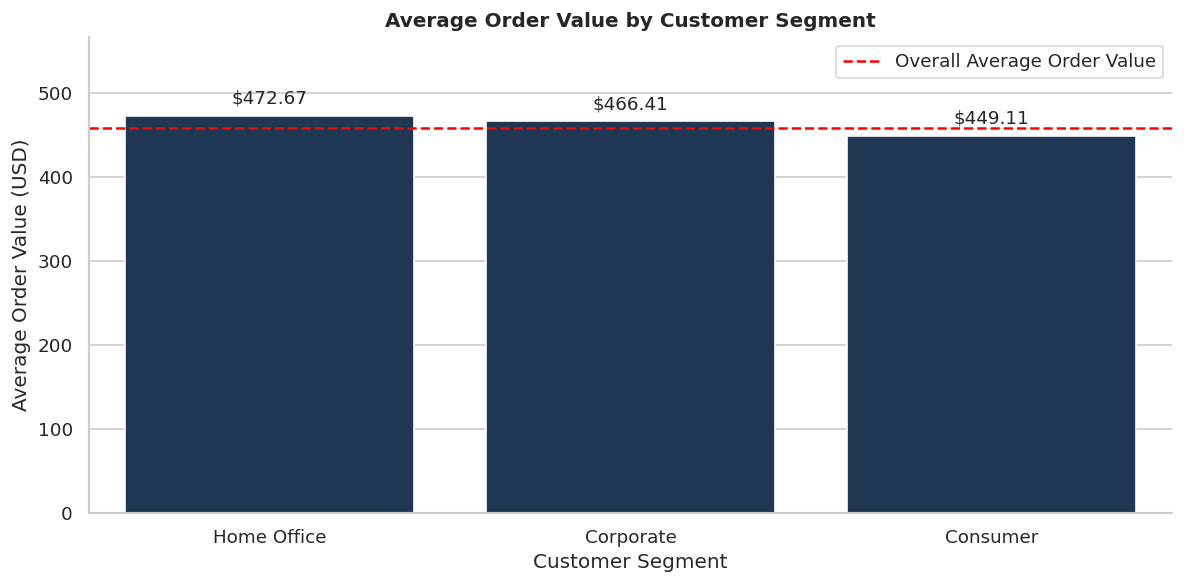

In [34]:
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=segment_performance.sort_values(
        'Average Order Value', ascending=False
    ),
    x='Segment',
    y='Average Order Value',
    color=primary_color
)

for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f'${v:,.2f}' for v in container.datavalues],
        padding=5
    )

plt.axhline(
    average_order_value,
    color='red',
    linestyle='--',
    label='Overall Average Order Value'
)

plt.title(
    'Average Order Value by Customer Segment',
    fontweight='bold'
)

plt.xlabel('Customer Segment')
plt.ylabel('Average Order Value (USD)')
plt.ylim(
    0,
    segment_performance['Average Order Value'].max() * 1.2
)

plt.legend()
sns.despine()
plt.tight_layout()
plt.show()

### Customer Segment Findings

The Consumer segment generated the highest revenue and total profit, contributing approximately 50.56% of overall company revenue. However, its profit margin of 11.55% was below the company-wide average.

The Home Office segment achieved the highest profit margin of 14.03% and the highest average order value of USD 472.67.

Meanwhile, the Corporate segment generated the highest revenue per customer at USD 2,992.15.

These findings suggest that the company should maintain its strong Consumer customer base while exploring targeted growth opportunities within the Corporate and Home Office segments.

### 4.7 Discount and Profitability Analysis

This section investigates the relationship between
discount levels and profitability using descriptive
statistics, correlation analysis, hypothesis testing,
and regression analysis.

The objective is to evaluate whether higher discounts
are associated with reduced profitability and identify
potential opportunities for improving pricing strategies.

In [35]:
correlation_matrix = df[
    ['Sales', 'Quantity', 'Discount',
     'Profit', 'Profit Margin']
].corr()

correlation_matrix.round(3)

,Sales,Quantity,Discount,Profit,Profit Margin
Sales,1.000,0.201,-0.028,0.479,0.003
Quantity,0.201,1.000,0.009,0.066,-0.005
Discount,-0.028,0.009,1.000,-0.219,-0.864
Profit,0.479,0.066,-0.219,1.000,0.224
Profit Margin,0.003,-0.005,-0.864,0.224,1.000


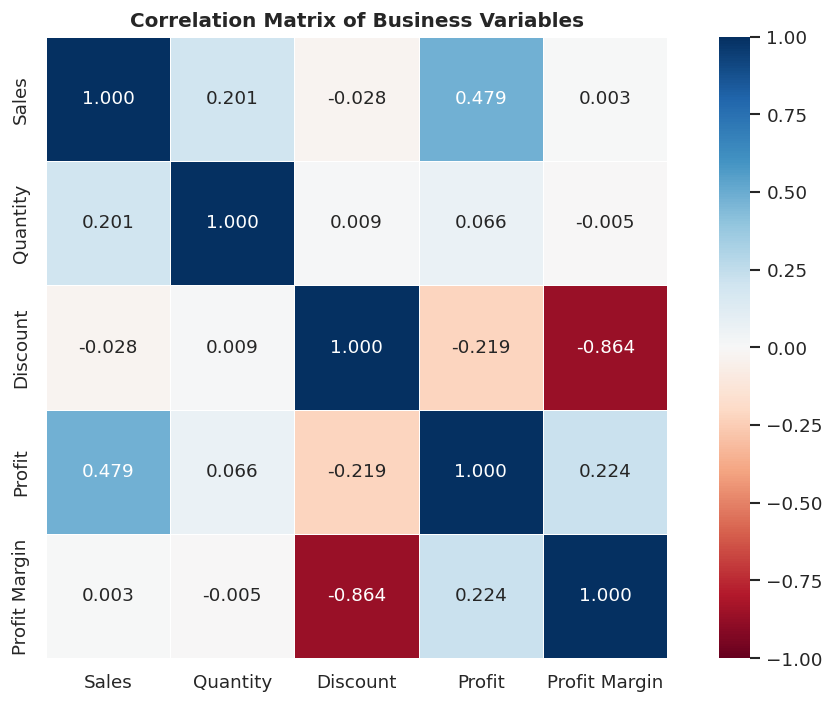

In [36]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.3f',
    cmap='RdBu',
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True
)

plt.title(
    'Correlation Matrix of Business Variables',
    fontweight='bold'
)

plt.tight_layout()
plt.show()

In [37]:
discount_performance = df.groupby('Discount').agg(
    Records=('Row ID', 'count'),
    Revenue=('Sales', 'sum'),
    Profit=('Profit', 'sum'),
    Average_Profit=('Profit', 'mean')
).reset_index()

discount_performance['Profit Margin (%)'] = (
    discount_performance['Profit'] /
    discount_performance['Revenue']
) * 100

discount_performance['Discount (%)'] = (
    discount_performance['Discount'] * 100
)

discount_performance[
    ['Discount (%)', 'Records', 'Revenue',
     'Profit', 'Average_Profit', 'Profit Margin (%)']
].round(2)

,Discount (%),Records,Revenue,Profit,Average_Profit,Profit Margin (%)
0,0.0,4798,1087908.47,320987.60,66.90,29.51
1,10.0,94,54369.35,9029.18,96.06,16.61
2,15.0,52,27558.52,1418.99,27.29,5.15
3,20.0,3657,764594.37,90337.31,24.70,11.82
4,30.0,227,103226.66,-10369.28,-45.68,-10.05
5,32.0,27,14493.46,-2391.14,-88.56,-16.50
6,40.0,206,116417.78,-23057.05,-111.93,-19.81
7,45.0,11,5484.97,-2493.11,-226.65,-45.45
8,50.0,66,58918.54,-20506.43,-310.70,-34.80
9,60.0,138,6644.70,-5944.66,-43.08,-89.46


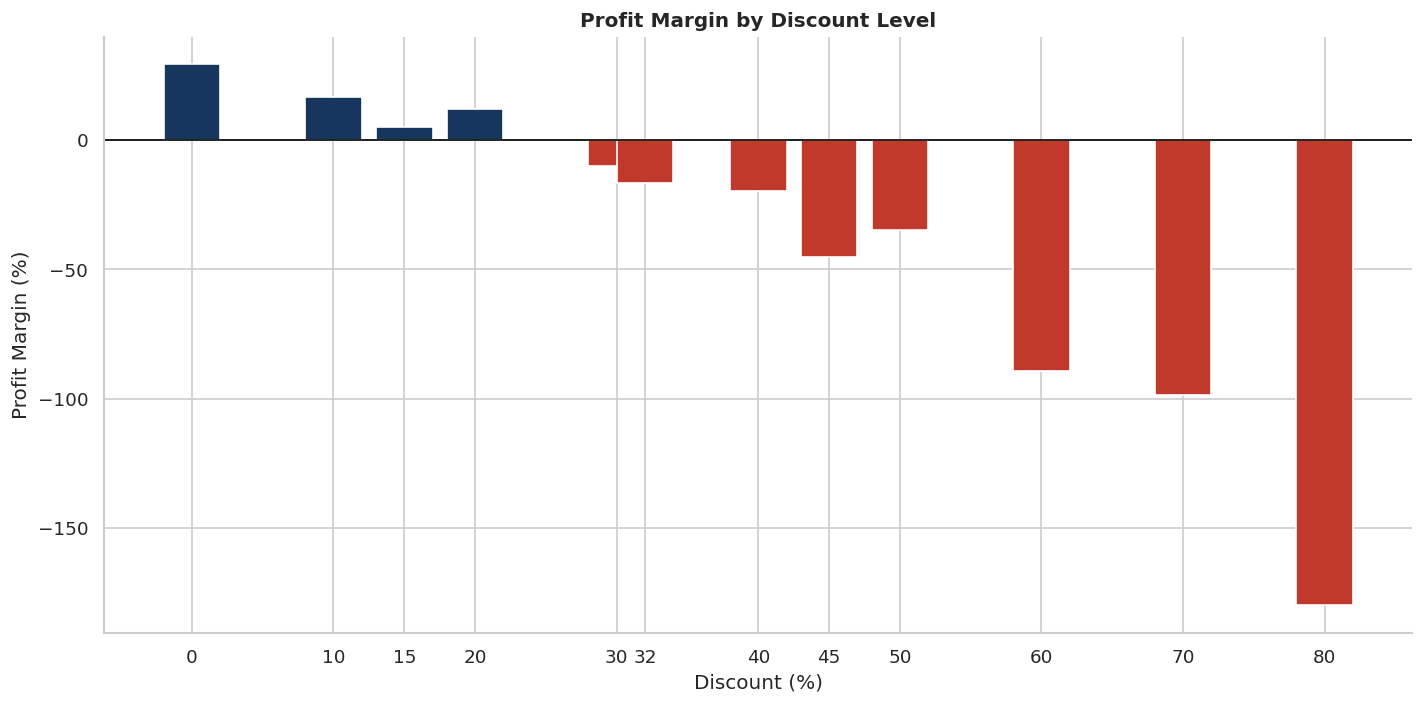

In [38]:
plt.figure(figsize=(12, 6))

colors = [
    primary_color if margin >= 0 else '#C0392B'
    for margin in discount_performance['Profit Margin (%)']
]

plt.bar(
    discount_performance['Discount (%)'],
    discount_performance['Profit Margin (%)'],
    color=colors,
    width=4
)

plt.axhline(0, color='black', linewidth=1)

plt.title(
    'Profit Margin by Discount Level',
    fontweight='bold'
)

plt.xlabel('Discount (%)')
plt.ylabel('Profit Margin (%)')
plt.xticks(discount_performance['Discount (%)'])

sns.despine()
plt.tight_layout()
plt.show()

### Discount and Profitability Findings

Correlation analysis revealed a strong negative relationship between discount levels and profit margins, with a Pearson correlation coefficient of -0.864. However, discounts demonstrated negligible linear correlations with sales and quantity at the order-line level.

Transactions without discounts achieved an aggregate profit margin of 29.51%, while every observed discount level of 30% or higher generated negative aggregate profitability.

These findings suggest that aggressive discounting may be associated with reduced profitability. Management should evaluate existing discount policies and investigate whether alternative pricing strategies could improve financial performance.

However, correlation does not establish causation, and further statistical analysis is necessary to account for differences in product categories and geographical regions.

## 5. Statistical Analysis and Hypothesis Testing

This section applies inferential statistics and
multiple linear regression to investigate the
relationship between discount strategies and
profitability.

In [39]:
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf


### 5.1 Pearson Correlation Hypothesis Test

H0: There is no linear correlation between
discount levels and profit margins.

H1: There is a significant linear correlation
between discount levels and profit margins.

Significance level: 0.05

In [40]:
r, p_value = stats.pearsonr(
    df['Discount'],
    df['Profit Margin']
)

print(f"Pearson Correlation: {r:.4f}")
print(f"P-value: {p_value:.4e}")

alpha = 0.05

if p_value < alpha:
    print("Decision: Reject the null hypothesis")
else:
    print("Decision: Fail to reject the null hypothesis")

Pearson Correlation: -0.8645
P-value: 0.0000e+00
Decision: Reject the null hypothesis


### 5.2 Independent Two-Sample t-Test

This test compares the average order-line profit
margins of low-discount and high-discount groups.

H0: The two groups have equal mean profit margins.

H1: The two groups have different mean profit margins.

In [41]:
low_discount = df.loc[
    df['Discount'] < 0.30, 'Profit Margin'
]

high_discount = df.loc[
    df['Discount'] >= 0.30, 'Profit Margin'
]

print("LOW DISCOUNT GROUP")
print(f"Records: {len(low_discount)}")
print(f"Mean Margin: {low_discount.mean():.2f}%")

print("\nHIGH DISCOUNT GROUP")
print(f"Records: {len(high_discount)}")
print(f"Mean Margin: {high_discount.mean():.2f}%")

t_stat, p_value = stats.ttest_ind(
    low_discount,
    high_discount,
    equal_var=False
)

print(f"\nT-statistic: {t_stat:.4f}")
print(f"P-value: {p_value:.4e}")

if p_value < 0.05:
    print("Decision: Reject the null hypothesis")
else:
    print("Decision: Fail to reject the null hypothesis")

LOW DISCOUNT GROUP
Records: 8601
Mean Margin: 26.69%

HIGH DISCOUNT GROUP
Records: 1393
Mean Margin: -78.45%

T-statistic: 59.6085
P-value: 0.0000e+00
Decision: Reject the null hypothesis


### 5.3 Multiple Linear Regression Analysis

A multiple linear regression model is developed
to examine the association between discounts and
profit margins while accounting for product
category, region, customer segment, and quantity.

In [42]:
regression_df = df.rename(columns={
    'Profit Margin': 'Profit_Margin'
}).copy()

regression_df['Discount_Pct'] = (
    regression_df['Discount'] * 100
)

model = smf.ols(
    formula='Profit_Margin ~ Discount_Pct + Quantity + C(Category) + C(Region) + C(Segment)',
    data=regression_df
).fit(
    cov_type='cluster',
    cov_kwds={
        'groups': regression_df['Customer ID']
    }
)

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:          Profit_Margin   R-squared:                       0.756
Model:                            OLS   Adj. R-squared:                  0.756
Method:                 Least Squares   F-statistic:                     1183.
Date:                Thu, 26 Nov 2026   Prob (F-statistic):               0.00
Time:                        00:28:31   Log-Likelihood:                -45535.
No. Observations:                9994   AIC:                         9.109e+04
Df Residuals:                    9984   BIC:                         9.116e+04
Df Model:                           9                                         
Covariance Type:              cluster                                         
                                     coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
Intercept   

### Statistical Analysis Findings

Pearson correlation analysis identified a strong negative relationship between discount levels and profit margins (r = -0.8645, p < 0.001).

Welch's two-sample t-test revealed a substantial difference between low-discount and high-discount transactions. The low-discount group achieved an average order-line profit margin of 26.69%, compared with -78.45% for the high-discount group.

The multiple linear regression model explained approximately 75.6% of the observed variation in profit margins. After accounting for product category, region, customer segment, and quantity, a one-percentage-point increase in discount was associated with a 1.92-percentage-point decrease in profit margin.

Product category and geographical region were statistically significant predictors, while customer segment and quantity were not statistically significant at the 5% significance level.

These findings support reviewing aggressive discounting practices and developing more targeted pricing strategies.

However, the results represent statistical associations rather than causal relationships. The hypothesis tests are exploratory due to potential dependence among observations and the data-driven selection of the discount threshold.

### 5.5 Regression Model Diagnostics

This section evaluates regression model assumptions
using residual analysis and diagnostic visualizations.

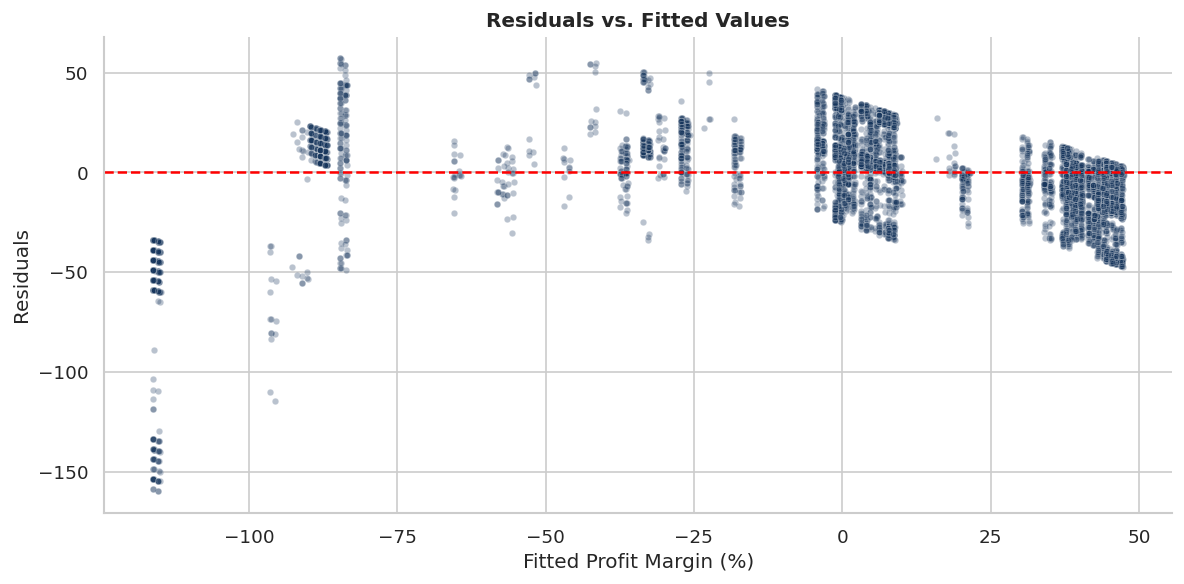

In [43]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    x=model.fittedvalues,
    y=model.resid,
    color=primary_color,
    alpha=0.3,
    s=15
)

plt.axhline(0, color='red', linestyle='--')

plt.title('Residuals vs. Fitted Values',
          fontweight='bold')

plt.xlabel('Fitted Profit Margin (%)')
plt.ylabel('Residuals')

sns.despine()
plt.tight_layout()
plt.show()

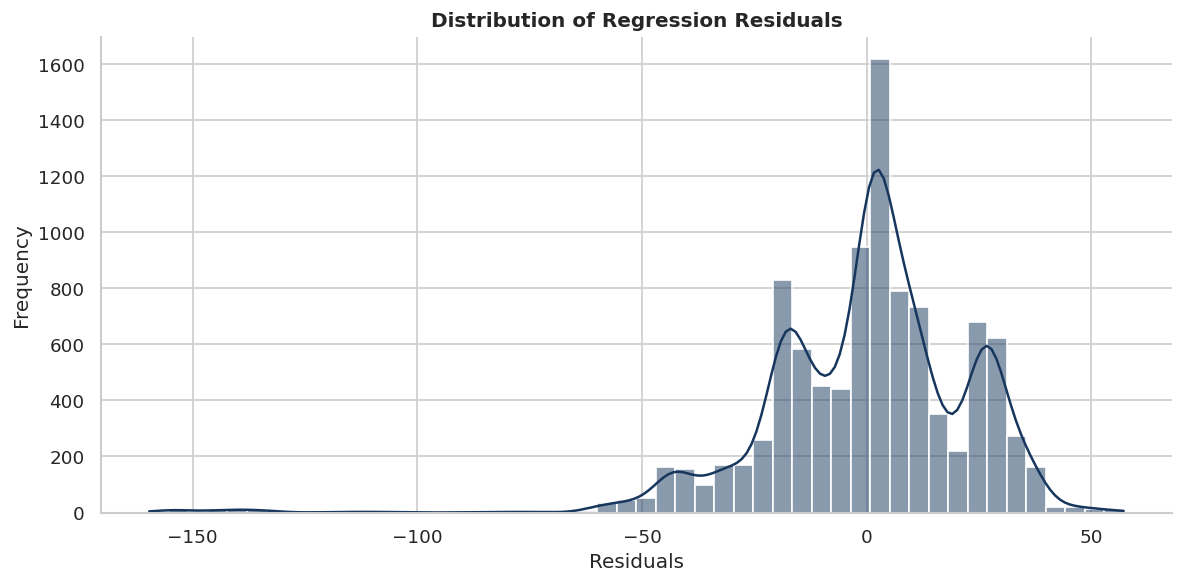

In [44]:
plt.figure(figsize=(10, 5))

sns.histplot(
    model.resid,
    bins=50,
    kde=True,
    color=primary_color
)

plt.title('Distribution of Regression Residuals',
          fontweight='bold')

plt.xlabel('Residuals')
plt.ylabel('Frequency')

sns.despine()
plt.tight_layout()
plt.show()

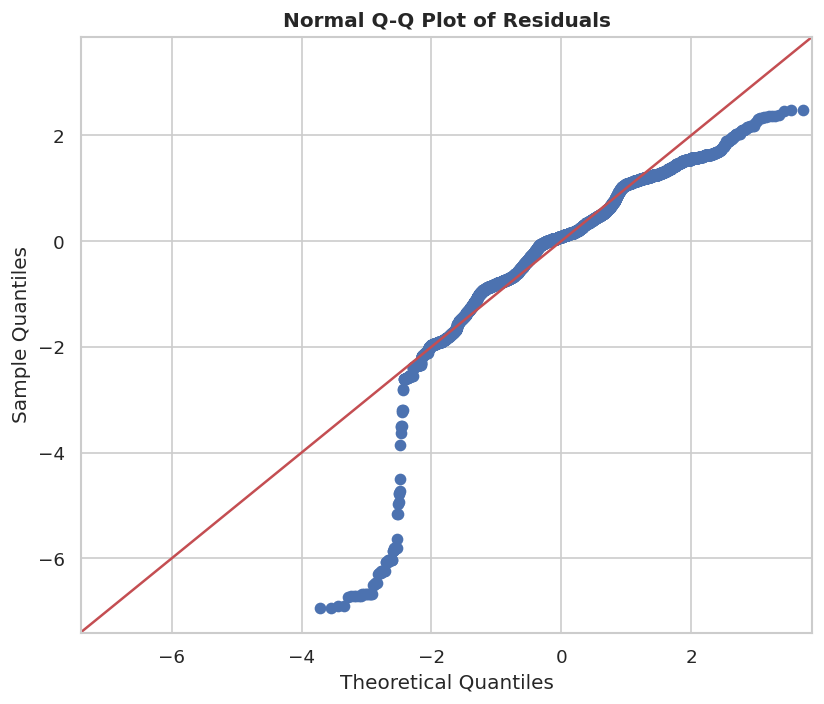

In [45]:
fig, ax = plt.subplots(figsize=(7, 6))

sm.qqplot(
    model.resid,
    line='45',
    fit=True,
    ax=ax
)

plt.title('Normal Q-Q Plot of Residuals',
          fontweight='bold')

plt.tight_layout()
plt.show()

### Regression Diagnostic Findings

The residuals versus fitted values plot reveals systematic patterns and unequal variance, suggesting potential nonlinearity and heteroscedasticity.

The residual distribution exhibits negative skewness, while the normal Q-Q plot demonstrates substantial deviations from normality, particularly in the lower tail.

Although the regression model explains 75.6% of the observed variation in profit margins, these diagnostic findings indicate that certain classical regression assumptions are not satisfied.

Customer-clustered standard errors were employed to improve the reliability of statistical inference. Nevertheless, the model should primarily be interpreted as an exploratory tool for understanding business relationships rather than establishing causality or making precise predictions.

## 6. SQL Business Analysis

This section utilizes SQL to extract business
insights from the retail dataset. SQL queries,
aggregations, common table expressions, and
window functions are applied to evaluate business
performance and identify strategic opportunities.

In [46]:
conn = sqlite3.connect(':memory:')

sql_df = df.copy()

sql_df.columns = (
    sql_df.columns
    .str.lower()
    .str.replace(' ', '_')
    .str.replace('-', '_')
)

sql_df.to_sql(
    'superstore',
    conn,
    if_exists='replace',
    index=False
)

print("SQL database created successfully.")

SQL database created successfully.


In [47]:
query = """
SELECT COUNT(*) AS total_records
FROM superstore;
"""

pd.read_sql_query(query, conn)

,total_records
0,9994


### 6.1 Business Performance Using SQL

This query calculates essential business performance
indicators and validates the results obtained
through Python-based analysis.

In [48]:
query = """
SELECT
    ROUND(SUM(sales), 2) AS total_revenue,
    ROUND(SUM(profit), 2) AS total_profit,
    COUNT(DISTINCT order_id) AS total_orders,
    COUNT(DISTINCT customer_id) AS total_customers,
    SUM(quantity) AS total_units,
    ROUND(
        SUM(profit) * 100.0 / SUM(sales), 2
    ) AS profit_margin,
    ROUND(
        SUM(sales) / COUNT(DISTINCT order_id), 2
    ) AS average_order_value
FROM superstore;
"""

pd.read_sql_query(query, conn)

,total_revenue,total_profit,total_orders,total_customers,total_units,profit_margin,average_order_value
0,2297200.86,286397.02,5009,793,37873,12.47,458.61


### 6.2 Product Category Performance Using SQL

In [49]:
query = """
SELECT
    category,
    ROUND(SUM(sales), 2) AS revenue,
    ROUND(SUM(profit), 2) AS profit,
    SUM(quantity) AS units_sold,
    ROUND(
        SUM(profit) * 100.0 / SUM(sales), 2
    ) AS profit_margin
FROM superstore
GROUP BY category
ORDER BY revenue DESC;
"""

pd.read_sql_query(query, conn)

,category,revenue,profit,units_sold,profit_margin
0,Technology,836154.03,145454.95,6939,17.40
1,Furniture,741999.80,18451.27,8028,2.49
2,Office Supplies,719047.03,122490.80,22906,17.04


### 6.3 Identification of Loss-Making Subcategories

In [50]:
query = """
SELECT
    sub_category,
    ROUND(SUM(sales), 2) AS revenue,
    ROUND(SUM(profit), 2) AS total_profit,
    ROUND(
        SUM(profit) * 100.0 / SUM(sales), 2
    ) AS profit_margin
FROM superstore
GROUP BY sub_category
HAVING SUM(profit) < 0
ORDER BY total_profit ASC;
"""

pd.read_sql_query(query, conn)

,sub_category,revenue,total_profit,profit_margin
0,Tables,206965.53,-17725.48,-8.56
1,Bookcases,114880.00,-3472.56,-3.02
2,Supplies,46673.54,-1189.10,-2.55


### 6.4 Customer Ranking Using CTEs and Window Functions

This section identifies high-value customers based on
total revenue, profitability, and purchasing frequency
using common table expressions and ranking functions.

In [51]:
query = """
WITH customer_summary AS (
    SELECT
        customer_id,
        customer_name,
        SUM(sales) AS revenue,
        SUM(profit) AS profit,
        COUNT(DISTINCT order_id) AS total_orders
    FROM superstore
    GROUP BY customer_id, customer_name
)

SELECT
    RANK() OVER (
        ORDER BY revenue DESC
    ) AS customer_rank,
    customer_id,
    customer_name,
    ROUND(revenue, 2) AS revenue,
    ROUND(profit, 2) AS profit,
    total_orders,
    ROUND(profit * 100.0 / revenue, 2)
        AS profit_margin
FROM customer_summary
ORDER BY customer_rank
LIMIT 10;
"""

pd.read_sql_query(query, conn)

,customer_rank,customer_id,customer_name,revenue,profit,total_orders,profit_margin
0,1,SM-20320,Sean Miller,25043.05,-1980.74,5,-7.91
1,2,TC-20980,Tamara Chand,19052.22,8981.32,5,47.14
2,3,RB-19360,Raymond Buch,15117.34,6976.10,6,46.15
3,4,TA-21385,Tom Ashbrook,14595.62,4703.79,4,32.23
4,5,AB-10105,Adrian Barton,14473.57,5444.81,10,37.62
5,6,KL-16645,Ken Lonsdale,14175.23,806.85,12,5.69
6,7,SC-20095,Sanjit Chand,14142.33,5757.41,9,40.71
7,8,HL-15040,Hunter Lopez,12873.30,5622.43,6,43.68
8,9,SE-20110,Sanjit Engle,12209.44,2650.68,11,21.71
9,10,CC-12370,Christopher Conant,12129.07,2177.05,5,17.95


### 6.5 Year-over-Year Revenue Growth Using SQL

The LAG() window function is used to compare annual
revenue with the previous year and evaluate business
growth over time.

In [52]:
query = """
WITH yearly_sales AS (
    SELECT
        year,
        SUM(sales) AS revenue,
        SUM(profit) AS profit
    FROM superstore
    GROUP BY year
),

growth_analysis AS (
    SELECT
        year,
        revenue,
        profit,
        LAG(revenue) OVER (
            ORDER BY year
        ) AS previous_revenue
    FROM yearly_sales
)

SELECT
    year,
    ROUND(revenue, 2) AS revenue,
    ROUND(profit, 2) AS profit,
    ROUND(previous_revenue, 2) AS previous_revenue,
    ROUND(
        (revenue - previous_revenue)
        * 100.0 / previous_revenue, 2
    ) AS revenue_growth_pct
FROM growth_analysis
ORDER BY year;
"""

pd.read_sql_query(query, conn)

,year,revenue,profit,previous_revenue,revenue_growth_pct
0,2014,484247.50,49543.97,NaN,NaN
1,2015,470532.51,61618.60,484247.50,-2.83
2,2016,609205.60,81795.17,470532.51,29.47
3,2017,733215.26,93439.27,609205.60,20.36


### 6.6 Regional Product Performance Ranking

This analysis identifies the most profitable product
subcategories within each geographical region using
partitioned SQL window functions.

In [53]:
query = """
WITH regional_products AS (
    SELECT
        region,
        sub_category,
        SUM(sales) AS revenue,
        SUM(profit) AS profit
    FROM superstore
    GROUP BY region, sub_category
),

ranked_products AS (
    SELECT
        region,
        sub_category,
        revenue,
        profit,
        DENSE_RANK() OVER (
            PARTITION BY region
            ORDER BY profit DESC
        ) AS profit_rank
    FROM regional_products
)

SELECT
    region,
    sub_category,
    ROUND(revenue, 2) AS revenue,
    ROUND(profit, 2) AS profit,
    profit_rank
FROM ranked_products
WHERE profit_rank <= 3
ORDER BY region, profit_rank;
"""

pd.read_sql_query(query, conn)

,region,sub_category,revenue,profit,profit_rank
0,Central,Copiers,37259.57,15608.84,1
1,Central,Phones,72403.28,12323.03,2
2,Central,Accessories,33956.08,7251.63,3
3,East,Copiers,53219.46,17022.84,1
4,East,Phones,100614.98,12314.69,2
5,East,Binders,53498.00,11267.93,3
6,South,Phones,58304.44,10767.28,1
7,South,Accessories,27276.75,7004.54,2
8,South,Chairs,45176.45,6612.09,3
9,West,Copiers,49749.24,19327.24,1


### 6.7 Discount Risk Analysis Using SQL

Conditional aggregation and CASE statements are used
to classify discount levels and evaluate financial
risk associated with aggressive discounting.

In [54]:
query = """
WITH discount_groups AS (
    SELECT
        CASE
            WHEN discount = 0 THEN 'No Discount'
            WHEN discount < 0.30 THEN 'Low Discount'
            WHEN discount < 0.50 THEN 'High Discount'
            ELSE 'Extreme Discount'
        END AS discount_group,
        sales,
        profit
    FROM superstore
)

SELECT
    discount_group,
    COUNT(*) AS total_records,
    ROUND(SUM(sales), 2) AS revenue,
    ROUND(SUM(profit), 2) AS profit,
    ROUND(
        SUM(profit) * 100.0 / SUM(sales), 2
    ) AS profit_margin,
    SUM(
        CASE WHEN profit < 0 THEN 1 ELSE 0 END
    ) AS loss_making_records,
    ROUND(
        100.0 * SUM(
            CASE WHEN profit < 0 THEN 1 ELSE 0 END
        ) / COUNT(*), 2
    ) AS loss_rate_pct
FROM discount_groups
GROUP BY discount_group
ORDER BY profit_margin DESC;
"""

pd.read_sql_query(query, conn)

,discount_group,total_records,revenue,profit,profit_margin,loss_making_records,loss_rate_pct
0,No Discount,4798,1087908.47,320987.60,29.51,0,0.00
1,Low Discount,3803,846522.24,100785.47,11.91,523,13.75
2,High Discount,471,239622.87,-38310.58,-15.99,426,90.45
3,Extreme Discount,922,123147.28,-97065.48,-78.82,922,100.00


### 6.8 Key SQL Findings

The SQL analysis successfully validated the business
performance metrics obtained through Python and
identified additional strategic insights.

- The highest-revenue customer generated a net loss
  of USD 1,980.74, demonstrating that revenue alone
  is not a reliable measure of customer value.

- Annual revenue growth reached 29.47% in 2016
  and 20.36% in 2017, indicating strong business
  expansion following a decline in 2015.

- Copiers were the most profitable product
  subcategory in three of the four regions.

- Discounts of 30% or higher generated combined
  net losses of USD 135,376.06.

- All 922 records with discounts of 50% or higher
  generated negative profits.

These findings suggest that the company should
prioritize profitability-based customer evaluation,
regional product strategies, and more disciplined
discount policies. However, the observed relationships
do not independently establish causation.

## 7. Data Export for Business Intelligence

The cleaned and transformed dataset is exported
for interactive dashboard development in Power BI.

In [55]:
df.to_csv('superstore_cleaned.csv', index=False)

print("Cleaned dataset exported successfully.")
print("Dataset dimensions:", df.shape)

Cleaned dataset exported successfully.
Dataset dimensions: (9994, 27)


In [56]:
from google.colab import files

files.download('superstore_cleaned.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>